# Canada on Fire: Seven Decades of Wildfire Patterns, Causes and Extremes
**COMP 6934: Introduction to Data Visualization · Fall 2026 · Group 15**

This notebook reproduces every figure in the report, in report order. All cleaning lives in `code/fire_data.py`, the visual system in `code/style.py`, and each figure is one function in `code/figures.py`. Running the notebook top to bottom regenerates `figures/*.pdf` (for LaTeX) and `figures/*.png` (previews).

**Data:** Canadian National Fire Database (CNFDB), Canadian Forest Service, Natural Resources Canada, https://cwfis.cfs.nrcan.gc.ca/en/fire-history, Open Government Licence – Canada. Point data `NFDB_point_20260811.txt`; burned-area polygons 1972–2024.

**Questions**
1. Is the area burned each year increasing, and how unusual was 2023?
2. How do lightning- and human-caused fires differ in where they happen, when they happen, and how big they get?
3. Do a small number of very large fires account for most of the burned area, and has the typical fire size changed by decade?
4. Where are Canada's main wildfire hotspots, and have they shifted over time?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("code").resolve()))

import matplotlib.pyplot as plt
import pandas as pd
import fire_data as fd
import style as st
import figures as F

st.apply()
%matplotlib inline

## 1. Data and cleaning decisions
- Years kept: 1950–2025 (drops `YEAR = -999` and 171 sparse pre-1950 records).
- Cause: H = Human, N = Lightning, U = Unknown (kept, shown in grey).
- Seasonal figures drop records with unknown month (`MONTH = 0`).
- Several agencies only report fully from the 1970s–80s, so trend figures shade the years before 1980.
- The burned-area polygons are simplified to 1 km by `code/prepare_geo.py`, which keeps 99.06% of the mapped area. Run that script once before the maps.

In [2]:
df = fd.load_fires()
print(f"{len(df):,} fires, {df.YEAR.min()}–{df.YEAR.max()}")
df.head()

448,447 fires, 1950–2025


,NFDBFIREID,SRC_AGENCY,LATITUDE,LONGITUDE,YEAR,MONTH,DAY,SIZE_HA,CAUSE,cause,agency,region,decade,size_class
0,AB-2024-CWF-001-2024,AB,50.066333,-114.154883,2024,1,2,0.05,H,Human,AB,Alberta,2020,<0.1 ha
1,AB-2024-HWF-001-2024,AB,57.912833,-116.334050,2024,1,5,0.40,H,Human,AB,Alberta,2020,0.1-1
2,AB-2024-SWF-001-2024,AB,56.575550,-115.216533,2024,1,17,0.01,H,Human,AB,Alberta,2020,<0.1 ha
3,AB-2024-LWF-001-2024,AB,55.957361,-110.709667,2024,1,9,0.01,H,Human,AB,Alberta,2020,<0.1 ha
4,AB-2024-LWF-002-2024,AB,55.957361,-110.709667,2024,1,9,0.01,H,Human,AB,Alberta,2020,<0.1 ha


In [3]:
summary = df.groupby("cause", observed=True).agg(
    fires=("SIZE_HA", "size"),
    area_Mha=("SIZE_HA", lambda s: s.sum() / 1e6),
    median_ha=("SIZE_HA", "median"))
summary.round(2)

,fires,area_Mha,median_ha
cause,,,
Lightning,195246,140.56,0.1
Human,242032,19.14,0.1
Unknown,11169,6.85,0.4


## 2. Q1: Is the area burned increasing, and how unusual was 2023?

### Figure 1: Fewer fires, more land burned
**Point this figure supports:** The 10-year average area burned has risen while the number of fires has fallen since the early 1990s; 2023 (17.6 Mha) burned about twice the next-worst year.

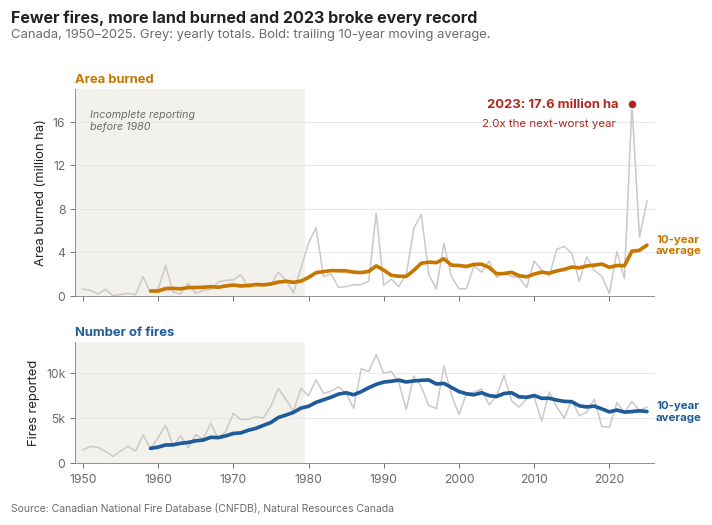

{'record_year': 2023,
 'record_mha': np.float64(17.606546667790017),
 'ratio': np.float64(2.022055268294876),
 'area_80s90s_mha': np.float64(2.780531480049223),
 'area_last20_mha': np.float64(3.650404568234849),
 'fires_80s90s': np.float64(8573.35),
 'fires_last20': np.float64(6277.95),
 'peak_fire_year_smoothed': 1996}

In [4]:
fig, facts = F.fig1_trend(df)
st.save(fig, "fig1_trend")
plt.show()
facts

### Figure 2: When the land burns
**Point this figure supports:** Burning is concentrated in May–August (97% of dated area). 2023 started early, with the largest May on record (6.5 Mha).

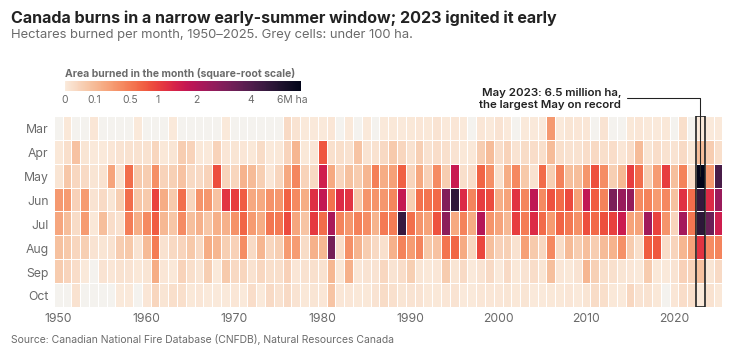

{'share_mar_oct': np.float64(0.9985247765878931),
 'may23_mha': np.float64(6.453021884680314),
 'may23_rank': 1,
 'share_may_aug': np.float64(0.974969560233395),
 'jun_jul_share': np.float64(0.7041168011056581)}

In [5]:
fig, facts = F.fig2_season_heatmap(df)
st.save(fig, "fig2_season_heatmap")
plt.show()
facts

### Figure 3: 2023 by jurisdiction
**Point this figure supports:** 2023 was national, not regional: Quebec, NWT, BC and Alberta each burned 2–4 Mha, together 77% of the year's total.

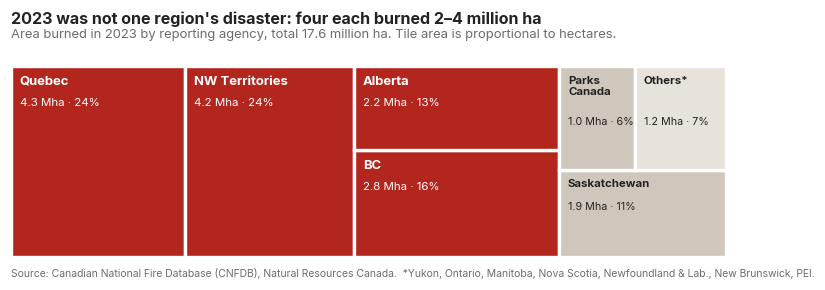

{'total_mha': np.float64(17.606546667790013),
 'top4': ['Quebec', 'NW Territories', 'BC', 'Alberta'],
 'top4_share': np.float64(0.767055060737999),
 'regions_over_1mha': 6}

In [6]:
fig, facts = F.fig3_treemap_2023(df)
st.save(fig, "fig3_treemap_2023")
plt.show()
facts

## 3. Q2: How do lightning and human fires differ?

### Figure 4: Share of fires vs share of area
**Point this figure supports:** People start 54% of fires but cause only 12% of the area burned; lightning starts 44% but burns 84%.

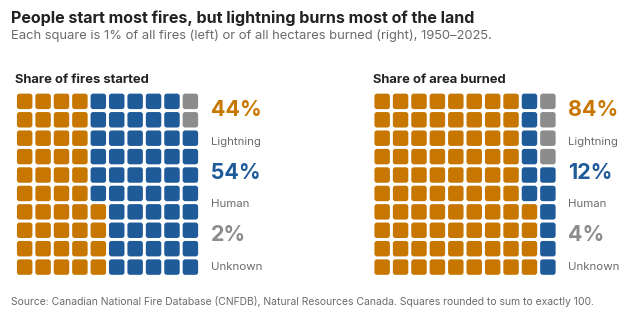

{'fire_share': {'Lightning': 0.435, 'Human': 0.54, 'Unknown': 0.025},
 'area_share': {'Lightning': 0.844, 'Human': 0.115, 'Unknown': 0.041},
 'mean_size': {'Lightning': 719.9, 'Human': 79.1, 'Unknown': 613.3}}

In [7]:
fig, facts = F.fig4_waffle_cause(df)
st.save(fig, "fig4_waffle_cause")
plt.show()
facts

### Figure 5: Two fire seasons
**Point this figure supports:** Human fires peak in May (spring, before green-up); 90% of lightning fires start in June–August.

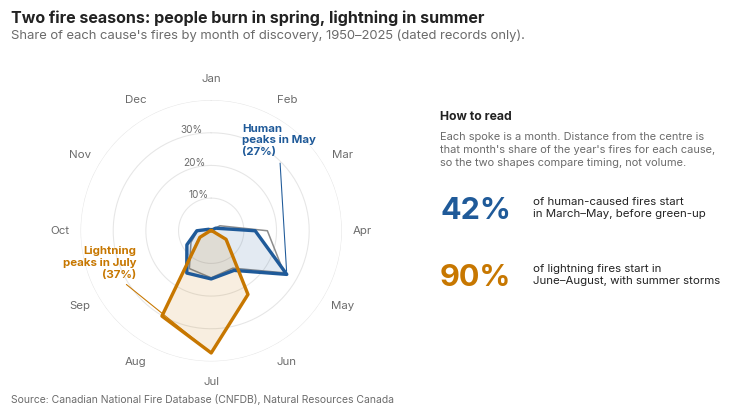

{'human_peak_month': 5,
 'lightning_peak_month': 7,
 'human_mar_may': np.float64(0.4174435766939395),
 'lightning_jun_aug': np.float64(0.9007085653346459)}

In [8]:
fig, facts = F.fig5_radar_season(df)
st.save(fig, "fig5_radar_season")
plt.show()
facts

### Figure 6: Where each cause burns
**Point this figure supports:** The NWT (96% lightning) and the Prairie provinces dominate area burned; the Maritimes barely burn.

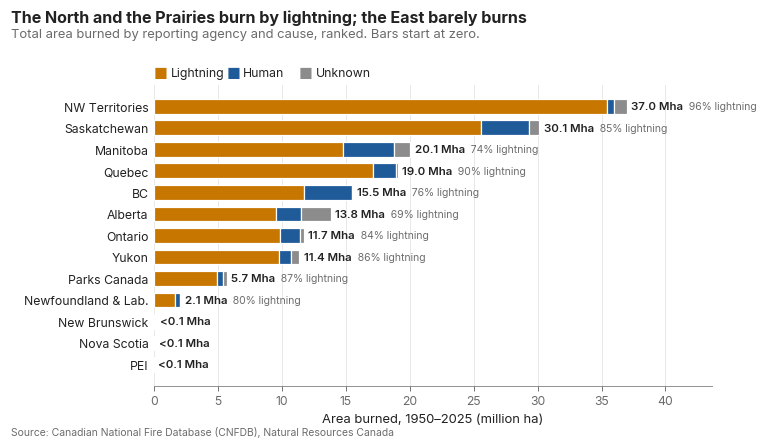

{'top': 'NW Territories',
 'top_mha': np.float64(36.96277458401061),
 'nt_lightning_share': np.float64(0.9591667098139315),
 'east_mha': np.float64(0.15490576901758346)}

In [9]:
fig, facts = F.fig6_region_cause(df)
st.save(fig, "fig6_region_cause")
plt.show()
facts

## 4. Q3: Do a few huge fires dominate, and has typical size changed?

### Figure 7: A few huge fires do almost all the burning
**Point this figure supports:** Fires of 200 ha or more are 4.8% of fires but 98.9% of the area burned; 72% of fires stay under 1 ha.

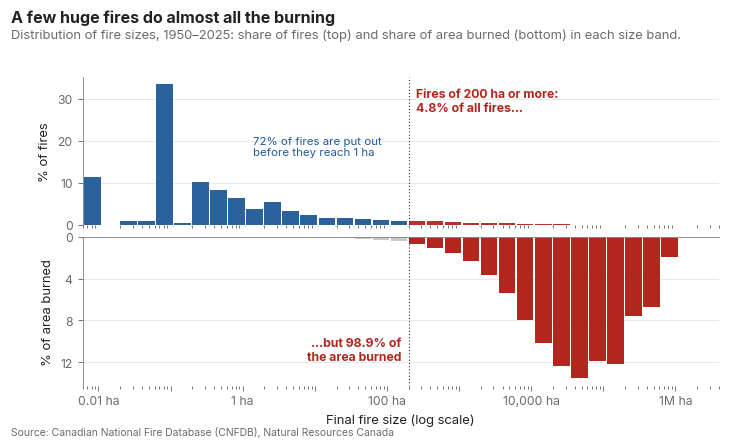

{'share_fires_ge200': np.float64(0.0481885261803513),
 'share_area_ge200': np.float64(0.989005337508843),
 'top1pct_area': np.float64(0.8467507869067077),
 'median_ha': np.float64(0.10000000149),
 'share_under_1ha': np.float64(0.7210506481256425)}

In [10]:
fig, facts = F.fig7_size_histogram(df)
st.save(fig, "fig7_size_histogram")
plt.show()
facts

### Figure 8: Escaped lightning fires are getting bigger
**Point this figure supports:** Among fires that grow past 1 ha, the median lightning fire rose from 6 ha (1990s) to 50 ha (2020s); human fires did not change.

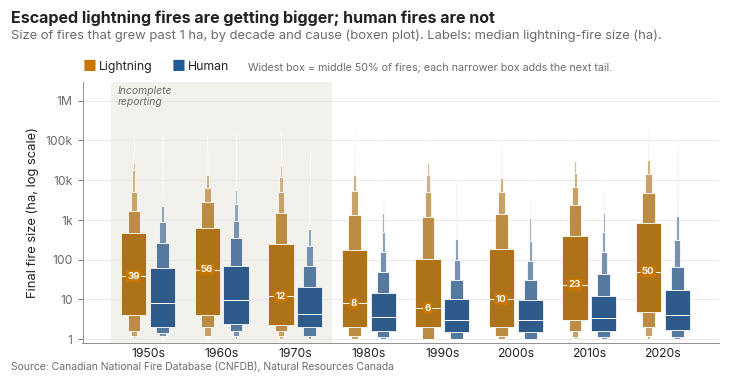

{'median': {'Lightning': {'1950s': 38.6,
   '1960s': 56.2,
   '1970s': 12.0,
   '1980s': 8.0,
   '1990s': 6.0,
   '2000s': 10.0,
   '2010s': 23.3,
   '2020s': 50.0},
  'Human': {'1950s': 8.0,
   '1960s': 9.7,
   '1970s': 4.4,
   '1980s': 3.5,
   '1990s': 3.0,
   '2000s': 3.0,
   '2010s': 3.4,
   '2020s': 4.0}},
 'p99': {'Lightning': {'1950s': 38316.0,
   '1960s': 33712.0,
   '1970s': 36282.0,
   '1980s': 47620.0,
   '1990s': 40042.0,
   '2000s': 31500.0,
   '2010s': 44205.0,
   '2020s': 87743.0},
  'Human': {'1950s': 12573.0,
   '1960s': 8655.0,
   '1970s': 2552.0,
   '1980s': 2465.0,
   '1990s': 2472.0,
   '2000s': 2310.0,
   '2010s': 3635.0,
   '2020s': 14761.0}}}

In [11]:
fig, facts = F.fig8_boxen_decade(df)
st.save(fig, "fig8_boxen_decade")
plt.show()
facts

## 5. Q4: Where are the hotspots, and have they shifted?

### Figure 9: Half a century of burn scars
**Point this figure supports:** Burning follows one boreal belt from Yukon to Quebec; the newest scars concentrate in the NWT, northern Alberta/Saskatchewan and northern Quebec.

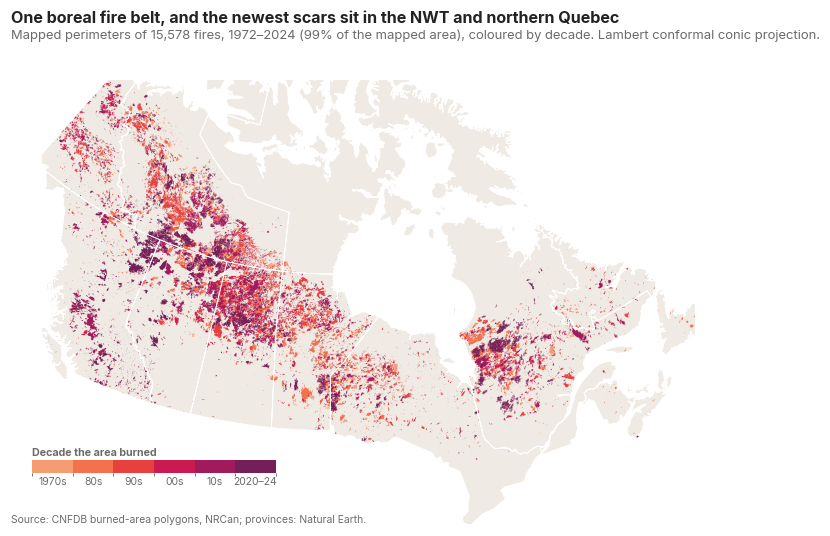

{'n_scars': 15578,
 'mha_by_decade': {1970: 10.1,
  1980: 26.8,
  1990: 25.4,
  2000: 16.3,
  2010: 27.7,
  2020: 27.3},
 'north60_share_1970s_90s': np.float64(0.3151926636090431),
 'north60_share_2000s_20s': np.float64(0.25812625571921183)}

In [12]:
fig, facts = F.fig9_burn_scars(df)
st.save(fig, "fig9_burn_scars")
plt.show()
facts

### Figure 10: Where fires start, by cause
**Point this figure supports:** Lightning ignitions spread across the remote interior; human ignitions trace roads, rivers and the populated south.

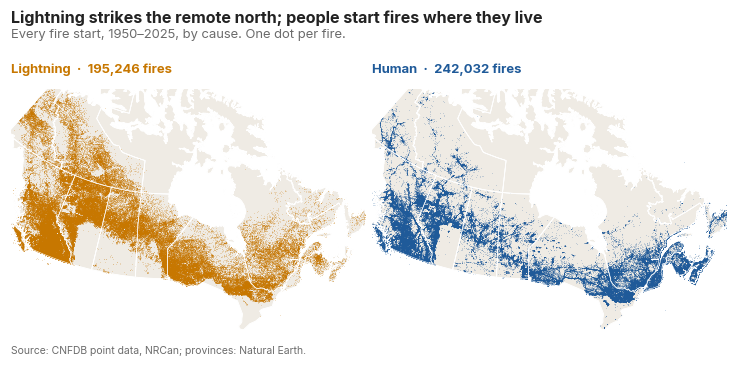

{'median_lat': {'Lightning': 52.23, 'Human': 50.21, 'Unknown': 51.73}}

In [13]:
fig, facts = F.fig10_ignition_maps(df)
st.save(fig, "fig10_ignition_maps")
plt.show()
facts

## 6. Conclusions (draft)
1. **Q1:** Area burned is rising even as fires become fewer, and 2023 was an outlier in both size and timing.
2. **Q2:** The two causes are different problems. Human fires are frequent, early-season and near people; lightning fires are fewer, mid-summer, remote, and responsible for most of the area.
3. **Q3:** Area burned is extremely concentrated in rare large fires, and the escaped lightning fires are getting larger.
4. **Q4:** The boreal belt is stable in location, but recent decades concentrate in the NWT and northern Quebec.